# SNN vs RNN Comparison Report

This notebook generates and inspects a structured JSON report for:
- confusion patterns (substitution/insertion/deletion structure)
- side-by-side decoding differences for matched utterances
- sentence-level similarity signals (BLEU / edit similarity / embedding cosine)

In [1]:
from collections import defaultdict
from math import comb
from pathlib import Path
import json
import re
import subprocess
import sys
import textwrap

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents]
PROJECT_ROOT = next((p for p in candidates if (p / "model_training").exists()), None)
if PROJECT_ROOT is None:
    raise RuntimeError(
        f"Could not locate repo root from cwd={cwd}. Expected a parent directory containing 'model_training'."
    )

print(f"Project root: {PROJECT_ROOT}")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


Project root: /home/alex/snn_for_bts/brain_to_text


In [2]:
RNN_RUN_DIR = PROJECT_ROOT / "model_training" / "logs" / "rnn" / "2026-04-02_17-52-59_035938_rnn_pid238051"
SNN_RUN_DIR = PROJECT_ROOT / "model_training" / "logs" / "snn/2026-04-04" / "2026-04-04_19-54-38_391644_snn_pid164025"
TOP_K = 25

OUTPUT_JSON = (
    PROJECT_ROOT
    / "model_training"
    / "logs"
    / f"compare_snn_vs_rnn_{RNN_RUN_DIR.name}__{SNN_RUN_DIR.name}.json"
)

assert RNN_RUN_DIR.exists(), f"Missing RNN run dir: {RNN_RUN_DIR}"
assert SNN_RUN_DIR.exists(), f"Missing SNN run dir: {SNN_RUN_DIR}"
print("RNN run:", RNN_RUN_DIR)
print("SNN run:", SNN_RUN_DIR)
print("Output JSON:", OUTPUT_JSON)


RNN run: /home/alex/snn_for_bts/brain_to_text/model_training/logs/rnn/2026-04-02_17-52-59_035938_rnn_pid238051
SNN run: /home/alex/snn_for_bts/brain_to_text/model_training/logs/snn/2026-04-04/2026-04-04_19-54-38_391644_snn_pid164025
Output JSON: /home/alex/snn_for_bts/brain_to_text/model_training/logs/compare_snn_vs_rnn_2026-04-02_17-52-59_035938_rnn_pid238051__2026-04-04_19-54-38_391644_snn_pid164025.json


In [3]:
cmd = [
    sys.executable,
    str(PROJECT_ROOT / "model_training" / "evaluate_model" / "compare_snn_rnn_results.py"),
    "--rnn-run-dir",
    str(RNN_RUN_DIR),
    "--snn-run-dir",
    str(SNN_RUN_DIR),
    "--top-k",
    str(TOP_K),
    "--output-json",
    str(OUTPUT_JSON),
]
print("Running:", " ".join(cmd))
subprocess.run(cmd, check=True)
print("Done.")


Running: /home/alex/miniconda3/envs/spikachu/bin/python /home/alex/snn_for_bts/brain_to_text/model_training/evaluate_model/compare_snn_rnn_results.py --rnn-run-dir /home/alex/snn_for_bts/brain_to_text/model_training/logs/rnn/2026-04-02_17-52-59_035938_rnn_pid238051 --snn-run-dir /home/alex/snn_for_bts/brain_to_text/model_training/logs/snn/2026-04-04/2026-04-04_19-54-38_391644_snn_pid164025 --top-k 25 --output-json /home/alex/snn_for_bts/brain_to_text/model_training/logs/compare_snn_vs_rnn_2026-04-02_17-52-59_035938_rnn_pid238051__2026-04-04_19-54-38_391644_snn_pid164025.json
Wrote comparison report to: /home/alex/snn_for_bts/brain_to_text/model_training/logs/compare_snn_vs_rnn_2026-04-02_17-52-59_035938_rnn_pid238051__2026-04-04_19-54-38_391644_snn_pid164025.json
Done.


In [4]:
with OUTPUT_JSON.open("r", encoding="utf-8") as f:
    report = json.load(f)

summary = {
    "shared_utterances": report["pairwise"]["num_shared_utterances"],
    "rnn_mean_sentence_per": report["model_level"]["rnn"]["aggregate"]["mean_sentence_per"],
    "snn_mean_sentence_per": report["model_level"]["snn"]["aggregate"]["mean_sentence_per"],
    "mean_abs_per_gap": report["pairwise"]["summary"]["mean_abs_per_gap"],
    "mean_abs_bert_gap": report["pairwise"]["summary"]["mean_abs_bert_gap"],
    "semantic_gap_small_flag": report["pairwise"]["summary"]["semantic_gap_small_flag"],
}
display(pd.DataFrame([summary]))


,shared_utterances,rnn_mean_sentence_per,snn_mean_sentence_per,mean_abs_per_gap,mean_abs_bert_gap,semantic_gap_small_flag
0,1426,0.102946,0.122887,0.048427,0.042916,False


Biggest decoding differences where SNN performs worse than RNN:


,ground_truth_words,snn_decoded_words,rnn_decoded_words,ground_truth_phonemes,snn_decoded_phonemes,rnn_decoded_phonemes,snn_minus_rnn_per,rnn_per,snn_per
0,when they fall over,wither than full ever,wen they fall over,W EH N | DH EY | F AO L | OW V ER |,W IH DH N | DH AH EY | F UH L | EH V ER |,W EH N | DH EY | F AO L | OW V ER |,0.333333,0.000000,0.333333
1,keep it clean please,p in lean play's,keep it clean pleas,K IY P | IH T | K L IY N | P L IY Z |,P | IH N | L IY N | P L EY Z |,K IY P | IH T | K L IY N | P L IY Z |,0.294118,0.000000,0.294118
2,kept touring shallows hang everyone,gap going salaries ib everyone,kett during chalets ang everyone,K EH P T | T UH R IH NG | SH AE L OW Z | ...,G EH P | G ER IH NG | S R AE L ER Z | IH...,K EH T | D UH R IH NG | SH AE L OW Z | A...,0.275862,0.103448,0.379310
3,all my aunts and uncles,ohl mai x and holocausts,all mai ants and alcon,AO L | M AY | AE N T S | AH N D | AH N...,OW L | M AY | EH T S | AH N D | HH AO ...,AO L | M AY | AE N T S | AH N D | AH L...,0.272727,0.181818,0.454545
4,how long have you been married,hao long halve ewe perin mast,hao long halve ewe been married,HH AW | L AO NG | HH AE V | Y UW | B I...,HH AW | L AO NG | HH AE V | Y UW | P E...,HH AW | L AO NG | HH AE V | Y UW | B I...,0.250000,0.000000,0.250000
5,he's an indoor cat,e's ahn indo get,he's ahn indoor cat,HH IY Z | AE N | IH N D AO R | K AE T |,IY Z | AE N | IH N D UW | G EH T |,HH IY Z | AE N | IH N D AO OY | K AE T |,0.235294,0.058824,0.294118
6,if you haven't slowed down,if ewe havin' loon nan,if ewe haven't clone down,IH F | Y UW | HH AE V AH N T | S L OW D ...,IH F | Y UW | HH AE V EY N | L UW N | ...,IH F | Y UW | HH AE V AH N T | K L OW N ...,0.227273,0.090909,0.318182
7,ten months later he said,ten munns lintel he said,ten month's later he said,T EH N | M AH N TH S | L EY T ER | HH IY...,T EH N | M AH N Z | L IH EY T AH L | HH ...,T EH N | M AH N TH S | L EY T ER | HH IY...,0.227273,0.000000,0.227273
8,we've had one as long as i can remember,y's at woods is long is a good remember,weaved had one as long as ai caen remember,W IY V | HH AE D | W AH N | AE Z | L A...,W AY V | AE T | W UH D N | IH Z | L AO...,W IY V D | HH AE D | W AH D | AE Z | L...,0.222222,0.083333,0.305556
9,he was a good player,he waas a gano parry,he waas a good pyre,HH IY | W AA Z | AH | G UH D | P L EY ...,HH IY | W AA Z | AH | G AA N T | P EH ...,HH IY | W AA Z | AH | G UH D | P AY ER...,0.222222,0.111111,0.333333


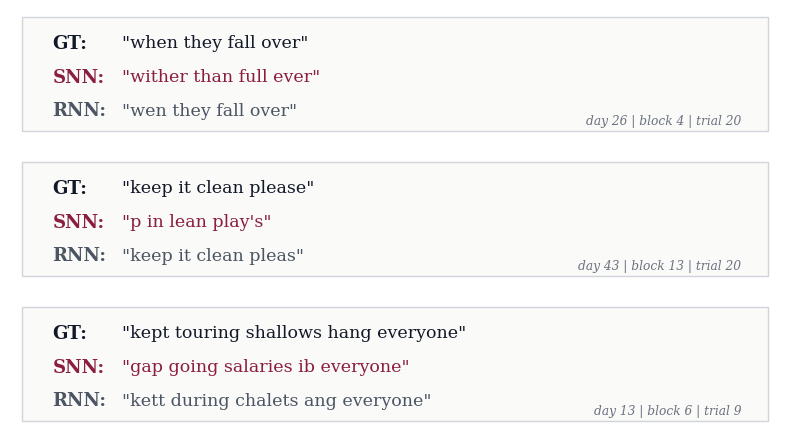

In [7]:
LEXICON_PATH = PROJECT_ROOT / "language_model" / "examples" / "speech" / "s0" / "dict.txt"

def normalize_phone(phone):
    return re.sub(r"\d", "", phone.strip())

def normalize_text(text):
    text = text.lower().strip()
    return re.sub(r"\s+", " ", re.sub(r"[^a-z' ]+", " ", text)).strip()

def load_pronunciation_lexicon(path):
    exact = {}
    by_first = defaultdict(list)
    with path.open("r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 2:
                continue
            word = parts[0].lower()
            if not re.search(r"[a-z]", word):
                continue
            phones = tuple(normalize_phone(p) for p in parts[1:] if normalize_phone(p))
            if not phones:
                continue
            exact.setdefault(phones, word)
            by_first[phones[0]].append((word, phones))
    return exact, by_first

EXACT_PRONUNCIATIONS, PRONUNCIATIONS_BY_FIRST = load_pronunciation_lexicon(LEXICON_PATH)

def split_phoneme_words(tokens):
    words = []
    current = []
    for token in tokens:
        t = token.strip()
        if t in {"|", "SIL"}:
            if current:
                words.append(tuple(current))
                current = []
            continue
        current.append(normalize_phone(t))
    if current:
        words.append(tuple(current))
    return words

def phoneme_edit_distance(a, b):
    dp = list(range(len(b) + 1))
    for i, tok_a in enumerate(a, start=1):
        prev_diag = dp[0]
        dp[0] = i
        for j, tok_b in enumerate(b, start=1):
            prev = dp[j]
            cost = 0 if tok_a == tok_b else 1
            dp[j] = min(dp[j] + 1, dp[j - 1] + 1, prev_diag + cost)
            prev_diag = prev
    return dp[-1]

def phoneme_words_to_text(tokens):
    chunks = split_phoneme_words(tokens)
    decoded_words = []
    for chunk in chunks:
        if not chunk:
            continue
        exact_word = EXACT_PRONUNCIATIONS.get(chunk)
        if exact_word is not None:
            decoded_words.append(exact_word)
            continue

        candidates = [
            candidate
            for candidate in PRONUNCIATIONS_BY_FIRST.get(chunk[0], [])
            if abs(len(candidate[1]) - len(chunk)) <= 2
        ]
        if not candidates:
            candidates = PRONUNCIATIONS_BY_FIRST.get(chunk[0], [])
        if not candidates:
            decoded_words.append("/".join(chunk).lower())
            continue

        best_word, _ = min(
            candidates,
            key=lambda candidate: (
                phoneme_edit_distance(chunk, candidate[1]),
                abs(len(candidate[1]) - len(chunk)),
                len(candidate[0]),
                candidate[0],
            ),
        )
        decoded_words.append(best_word)
    return " ".join(decoded_words)

def flatten_examples(items):
    rows = []
    for x in items:
        rows.append(
            {
                "day": x["key"]["day_index"],
                "block": x["key"]["block_num"],
                "trial": x["key"]["trial_num"],
                "ground_truth_text": x["transcription"],
                "ground_truth_words": normalize_text(x["transcription"]),
                "rnn_decoded_words": phoneme_words_to_text(x["rnn"]["pred_phonemes"]),
                "snn_decoded_words": phoneme_words_to_text(x["snn"]["pred_phonemes"]),
                "abs_per_gap": x["delta"]["abs_per_gap"],
                "snn_minus_rnn_per": x["delta"]["snn_minus_rnn_per"],
                "rnn_per": x["rnn"]["per"],
                "snn_per": x["snn"]["per"],
                "ground_truth_phonemes": " ".join(x["true_phonemes"]),
                "rnn_decoded_phonemes": " ".join(x["rnn"]["pred_phonemes"]),
                "snn_decoded_phonemes": " ".join(x["snn"]["pred_phonemes"]),
                "rnn_vs_snn_bleu": x["delta"]["rnn_vs_snn_bleu"],
                "rnn_vs_snn_edit_similarity": x["delta"]["rnn_vs_snn_edit_similarity"],
                "rnn_vs_snn_embedding_cosine": x["delta"]["rnn_vs_snn_embedding_cosine"],
            }
        )
    return pd.DataFrame(rows)

def render_decoding_cards(df, limit=3, title=None):
    sample = df.head(limit).reset_index(drop=True)
    if len(sample) == 0:
        return

    fig_height = max(1.4 * len(sample) + 0.3, 2.5)
    fig, axes = plt.subplots(len(sample), 1, figsize=(8, fig_height))
    if len(sample) == 1:
        axes = [axes]

    fig.patch.set_facecolor("#ffffff")
    if title is not None:
        fig.suptitle(title, color="#111827", fontsize=16, y=0.995, fontweight="semibold", fontfamily="DejaVu Serif")

    for ax, (_, row) in zip(axes, sample.iterrows()):
        ax.set_facecolor("#efefec")
        ax.axis("off")
        ax.add_patch(
            plt.Rectangle(
                (0.015, 0.06),
                0.97,
                0.88,
                transform=ax.transAxes,
                facecolor="#fafaf8",
                edgecolor="#d1d5db",
                linewidth=1.0,
                zorder=0,
            )
        )

        lines = [
            ("GT", row["ground_truth_words"], "#111827"),
            ("SNN", row["snn_decoded_words"], "#8b1e3f"),
            ("RNN", row["rnn_decoded_words"], "#4b5563"),
        ]
        y_positions = [0.74, 0.48, 0.22]
        for (label, text, color), y in zip(lines, y_positions):
            wrapped_text = textwrap.fill(str(text), width=52)
            ax.text(0.055, y, f"{label}:", color=color, fontsize=13.0, fontweight="semibold", family="DejaVu Serif", va="center")
            ax.text(0.145, y, f'"{wrapped_text}"', color=color, fontsize=12.6, family="DejaVu Serif", va="center", linespacing=1.15)

        meta = f"day {int(row['day'])} | block {int(row['block'])} | trial {int(row['trial'])}"
        ax.text(0.95, 0.09, meta, color="#6b7280", fontsize=8.8, family="DejaVu Serif", style="italic", ha="right", va="bottom")

    plt.tight_layout(rect=(0, 0, 1, 0.98 if title is not None else 1))
    plt.show()

largest_df = (
    flatten_examples(report["pairwise"]["largest_decoding_differences"])
    .query("snn_minus_rnn_per > 0")
    .sort_values(["snn_minus_rnn_per", "abs_per_gap", "snn_per"], ascending=[False, False, False])
    .reset_index(drop=True)
)
side_by_side_cols = [
    "ground_truth_words",
    "snn_decoded_words",
    "rnn_decoded_words",
    "ground_truth_phonemes",
    "snn_decoded_phonemes",
    "rnn_decoded_phonemes",
    "snn_minus_rnn_per",
    "rnn_per",
    "snn_per",
]

print("Biggest decoding differences where SNN performs worse than RNN:")
display(largest_df[side_by_side_cols].head(20))
render_decoding_cards(largest_df, limit=min(3, len(largest_df)))


In [6]:
# PER-focused decoding examples: median, worst gap, and best SNN

from model_training.evaluate_model.compare_snn_rnn_results import flatten_metrics, load_pickle

try:
    from scipy.stats import wilcoxon
except ImportError:
    wilcoxon = None

def parse_session_names(config_path):
    sessions = []
    in_sessions = False
    with config_path.open("r", encoding="utf-8") as f:
        for line in f:
            stripped = line.strip()
            if stripped.startswith("sessions:"):
                in_sessions = True
                continue
            if in_sessions:
                if line.startswith("  - "):
                    sessions.append(line.split("-", 1)[1].strip())
                elif stripped.startswith("dataset_probability_val:") or not line.startswith("  "):
                    break
    return sessions

SESSION_NAMES = parse_session_names(RNN_RUN_DIR / "configs" / "trainer_config_input.yaml")
DAY_TO_SESSION = {day: session for day, session in enumerate(SESSION_NAMES)}

rnn_rows = flatten_metrics(load_pickle(RNN_RUN_DIR / "checkpoints" / "val_metrics.pkl"))
snn_rows = flatten_metrics(load_pickle(SNN_RUN_DIR / "checkpoints" / "val_metrics.pkl"))

def build_pair_example_df(rnn_rows, snn_rows):
    rnn_map = {row["key"]: row for row in rnn_rows}
    snn_map = {row["key"]: row for row in snn_rows}
    shared_keys = sorted(set(rnn_map) & set(snn_map), key=lambda k: (k.day_index, k.block_num, k.trial_num))
    rows = []
    for key in shared_keys:
        r = rnn_map[key]
        s = snn_map[key]
        rows.append(
            {
                "day": key.day_index,
                "block": key.block_num,
                "trial": key.trial_num,
                "ground_truth_text": r["transcription"] or s["transcription"],
                "ground_truth_words": normalize_text(r["transcription"] or s["transcription"]),
                "ground_truth_phonemes": " ".join(r["true_tokens"]),
                "rnn_decoded_words": phoneme_words_to_text(r["pred_tokens"]),
                "snn_decoded_words": phoneme_words_to_text(s["pred_tokens"]),
                "rnn_decoded_phonemes": " ".join(r["pred_tokens"]),
                "snn_decoded_phonemes": " ".join(s["pred_tokens"]),
                "rnn_per": r["per"],
                "snn_per": s["per"],
                "snn_minus_rnn_per": s["per"] - r["per"],
                "abs_per_gap": abs(s["per"] - r["per"]),
            }
        )
    return pd.DataFrame(rows)

per_examples_df = build_pair_example_df(rnn_rows, snn_rows)
if len(per_examples_df) > 0:
    worst_gap_idx = (
        per_examples_df
        .query("snn_minus_rnn_per > 0")
        .sort_values(["snn_minus_rnn_per", "snn_per", "abs_per_gap"], ascending=[False, False, False])
        .head(3)
        .index
    )
    worst_gap_df = per_examples_df.loc[worst_gap_idx].reset_index(drop=True)

    remaining_after_worst = per_examples_df.loc[
        ~per_examples_df.index.isin(worst_gap_idx)
    ].copy()

    best_snn_idx = (
        remaining_after_worst
        .sort_values(["snn_per", "rnn_per", "abs_per_gap"], ascending=[True, True, True])
        .head(3)
        .index
    )
    best_snn_df = remaining_after_worst.loc[best_snn_idx].reset_index(drop=True)

    remaining_after_best = remaining_after_worst.loc[
        ~remaining_after_worst.index.isin(best_snn_idx)
    ].copy()

    median_source_df = remaining_after_best.sort_values(["snn_per", "abs_per_gap"], ascending=[True, True]).reset_index(drop=True)
    median_center = len(median_source_df) // 2
    median_start = max(0, median_center - 1)
    median_end = min(len(median_source_df), median_start + 3)
    median_start = max(0, median_end - 3)
    median_per_df = median_source_df.iloc[median_start:median_end].reset_index(drop=True)

    render_decoding_cards(
        median_per_df,
        limit=3,
        title="Typical decoding differences (median SNN PER cases):",
    )
    render_decoding_cards(
        worst_gap_df,
        limit=3,
        title="Worst decoding differences (largest SNN-RNN PER gap):",
    )
    render_decoding_cards(
        best_snn_df,
        limit=3,
        title="Best SNN decoding cases (lowest SNN PER):",
    )
else:
    print("No paired utterances were available for the PER-based visualizations.")

def summarize_by_session(rows, model_name):
    grouped = {}
    for row in rows:
        day = row["key"].day_index
        session = DAY_TO_SESSION.get(day, f"day_{day}")
        session_stats = grouped.setdefault(
            (day, session),
            {
                "day": day,
                "session": session,
                "model": model_name,
                "n_utterances": 0,
                "total_edit_distance": 0.0,
                "total_true_tokens": 0,
                "bleu_scores": [],
                "bert_scores": [],
            },
        )
        session_stats["n_utterances"] += 1
        session_stats["total_edit_distance"] += row["edit_distance"]
        session_stats["total_true_tokens"] += len(row["true_tokens"])
        session_stats["bleu_scores"].append(row["bleu_to_true"])
        session_stats["bert_scores"].append(row["bert_to_true"])

    session_rows = []
    for stats in grouped.values():
        session_rows.append(
            {
                "day": stats["day"],
                "session": stats["session"],
                "model": stats["model"],
                "n_utterances": stats["n_utterances"],
                "session_per": stats["total_edit_distance"] / max(stats["total_true_tokens"], 1),
                "session_bleu": sum(stats["bleu_scores"]) / max(len(stats["bleu_scores"]), 1),
                "session_bert": sum(stats["bert_scores"]) / max(len(stats["bert_scores"]), 1),
            }
        )
    return pd.DataFrame(session_rows).sort_values(["day", "session"]).reset_index(drop=True)

rnn_session_df = summarize_by_session(rnn_rows, "RNN")
snn_session_df = summarize_by_session(snn_rows, "SNN")

session_compare_df = (
    rnn_session_df.merge(
        snn_session_df,
        on=["day", "session"],
        suffixes=("_rnn", "_snn"),
        how="inner",
    )
    .sort_values(["day", "session"])
    .reset_index(drop=True)
)
session_compare_df["per_snn_minus_rnn"] = session_compare_df["session_per_snn"] - session_compare_df["session_per_rnn"]
session_compare_df["bleu_snn_minus_rnn"] = session_compare_df["session_bleu_snn"] - session_compare_df["session_bleu_rnn"]
session_compare_df["bert_snn_minus_rnn"] = session_compare_df["session_bert_snn"] - session_compare_df["session_bert_rnn"]

print("Per-session metric summary:")
display(
    session_compare_df[
        [
            "day",
            "session",
            "n_utterances_rnn",
            "session_per_rnn",
            "session_per_snn",
            "session_bleu_rnn",
            "session_bleu_snn",
            "session_bert_rnn",
            "session_bert_snn",
        ]
    ].round(4)
)

def sign_test_pvalue(diffs, zero_tol=1e-12):
    nonzero = [float(d) for d in diffs if abs(float(d)) > zero_tol]
    n = len(nonzero)
    if n == 0:
        return float("nan"), 0
    positives = sum(d > 0 for d in nonzero)
    tail = min(positives, n - positives)
    p_value = min(1.0, 2.0 * sum(comb(n, k) for k in range(tail + 1)) / (2 ** n))
    return float(p_value), n

def better_model_from_delta(delta, higher_is_better):
    if abs(delta) < 1e-12:
        return "Tie"
    if higher_is_better:
        return "SNN" if delta > 0 else "RNN"
    return "RNN" if delta > 0 else "SNN"

def paired_metric_test(df, metric_label, delta_col, higher_is_better):
    diffs = [float(x) for x in df[delta_col].dropna().tolist()]
    nonzero_diffs = [x for x in diffs if abs(x) > 1e-12]
    if wilcoxon is not None and nonzero_diffs:
        stat, p_value = wilcoxon(nonzero_diffs, alternative="two-sided", zero_method="wilcox", method="auto")
        test_name = "Wilcoxon signed-rank"
        n_used = len(nonzero_diffs)
    else:
        stat = float("nan")
        p_value, n_used = sign_test_pvalue(diffs)
        test_name = "Paired sign test"

    mean_delta = sum(diffs) / max(len(diffs), 1)
    return {
        "metric": metric_label,
        "test": test_name,
        "n_sessions": len(diffs),
        "n_nonzero_sessions": n_used,
        "rnn_mean": float(df[f"session_{metric_label.lower()}_rnn"].mean()),
        "snn_mean": float(df[f"session_{metric_label.lower()}_snn"].mean()),
        "mean_delta_snn_minus_rnn": mean_delta,
        "p_value": p_value,
        "significant_at_0_05": bool(p_value < 0.05) if pd.notna(p_value) else False,
        "better_model_by_mean": better_model_from_delta(mean_delta, higher_is_better=higher_is_better),
    }

significance_df = pd.DataFrame(
    [
        paired_metric_test(session_compare_df, "per", "per_snn_minus_rnn", higher_is_better=False),
        paired_metric_test(session_compare_df, "bleu", "bleu_snn_minus_rnn", higher_is_better=True),
        paired_metric_test(session_compare_df, "bert", "bert_snn_minus_rnn", higher_is_better=True),
    ]
)
print("Paired session-level significance tests:")
display(significance_df.round(4))

rnn_agg = report["model_level"]["rnn"]["aggregate"]
snn_agg = report["model_level"]["snn"]["aggregate"]

RNN_COLOR = "#000000"
SNN_COLOR = "#8B0000"

def annotate_bars(ax, bars, fmt, fontsize=12):
    y_max = ax.get_ylim()[1]
    offset = y_max * 0.02
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + offset,
            fmt.format(height),
            ha="center",
            va="bottom",
            fontsize=fontsize,
        )

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

# Plot 1: PER side-by-side
models = ["RNN", "SNN"]
pers = [rnn_agg["mean_sentence_per"], snn_agg["mean_sentence_per"]]
per_bars = axes[0].bar(models, pers, color=[RNN_COLOR, SNN_COLOR], width=0.6)
axes[0].set_title("Mean sentence PER: RNN vs SNN", fontsize=14)
axes[0].set_ylabel("PER", fontsize=13)
axes[0].set_ylim(0, max(pers) * 1.2)
axes[0].tick_params(axis="both", labelsize=12)
annotate_bars(axes[0], per_bars, "{:.4f}")

# Plot 2: error structure side-by-side
cats = ["Substitutions", "Insertions", "Deletions"]
rnn_counts = [rnn_agg["total_substitutions"], rnn_agg["total_insertions"], rnn_agg["total_deletions"]]
snn_counts = [snn_agg["total_substitutions"], snn_agg["total_insertions"], snn_agg["total_deletions"]]
x = range(len(cats))
w = 0.36
rnn_bars = axes[1].bar([i - w / 2 for i in x], rnn_counts, width=w, label="RNN", color=RNN_COLOR)
snn_bars = axes[1].bar([i + w / 2 for i in x], snn_counts, width=w, label="SNN", color=SNN_COLOR)
axes[1].set_xticks(list(x))
axes[1].set_xticklabels(cats, fontsize=12)
axes[1].set_title("Error structure: RNN vs SNN", fontsize=14)
axes[1].set_ylabel("Count", fontsize=13)
axes[1].tick_params(axis="y", labelsize=12)
axes[1].set_ylim(0, max(rnn_counts + snn_counts) * 1.16)
annotate_bars(axes[1], rnn_bars, "{:.0f}")
annotate_bars(axes[1], snn_bars, "{:.0f}")
axes[1].legend(fontsize=12)

plt.tight_layout()
plt.show()


KeyboardInterrupt: 

In [ ]:
error_table = pd.DataFrame(
    [
        {
            "model": "RNN",
            "mean_sentence_per": rnn_agg["mean_sentence_per"],
            "substitutions": rnn_agg["total_substitutions"],
            "insertions": rnn_agg["total_insertions"],
            "deletions": rnn_agg["total_deletions"],
            "sub_ratio": rnn_agg["substitution_ratio"],
            "ins_ratio": rnn_agg["insertion_ratio"],
            "del_ratio": rnn_agg["deletion_ratio"],
        },
        {
            "model": "SNN",
            "mean_sentence_per": snn_agg["mean_sentence_per"],
            "substitutions": snn_agg["total_substitutions"],
            "insertions": snn_agg["total_insertions"],
            "deletions": snn_agg["total_deletions"],
            "sub_ratio": snn_agg["substitution_ratio"],
            "ins_ratio": snn_agg["insertion_ratio"],
            "del_ratio": snn_agg["deletion_ratio"],
        },
    ]
)
display(error_table)
